## Árbol de decisión de clasificación (`max_depth=4`): gráficos, escalamiento, diagramas y reglas

**Resumen ejecutivo**

- **Pregunta.** Dada una región-año del cuadro maestro (2015-2020) descrita únicamente por su
  **actividad inmobiliaria** (`n_transacciones`, `precio_var_pct`), sus **anomalías climáticas**
  (`tmax_anom`, `tmin_anom`, `lluvia_anom`, `sol_anom`, `af_anom`) y su **región** —sin precio
  ni salario, que son la materia prima de la etiqueta—, ¿qué reglas jerárquicas de hasta
  **4 niveles de profundidad (`max_depth=4`)** permiten clasificar si un joven (18-34 años)
  enfrentará un **esfuerzo hipotecario ALTO** o **MODERADO**, y qué ganancia aporta el cuarto
  nivel frente al árbol de profundidad 3 y al árbol sin límite?
- **Etiqueta (`y`).** `Alto` si `esfuerzo >= mediana = 0,5636`; clases balanceadas
  **30/30**. El umbral del 30 % de `config` era inviable: las **60 de 60** filas caen
  en la misma clase.
- **Escalamiento e invarianza.** Se comparan **4 esquemas** (`Crudo`, `StandardScaler`,
  `MinMaxScaler` y `RobustScaler`) ajustados solo en entrenamiento. Se demuestra con `assert`
  que el árbol CART (`max_depth=4`) es **invariante a transformaciones monótonas** (idéntico
  accuracy en train `0,976`, test `0,944`, CV-5 `0,783` y 15 nodos), y se presenta la tabla
  de conversión exacta de sus umbrales de corte en cada escala.
- **Resultados (`max_depth=4`).** Train **0,976** / test **0,944** (brecha 0,032),
  CV-5 estratificada **0,783** (15 nodos, 8 hojas). Supera en test a profundidad 3 (`0,778`)
  y evita la memorización total del árbol sin límite (`train = 1,000`, `CV-5 = 0,767`).
- **Reglas (`max_depth=4`).** (1) mercado <= 97.888,5 transacciones/año → **Moderado** (20 de 25,
  80,0 %; y **100 % Moderado** cuando `sol_anom <= 4,19`, salvo repunte anual `precio_var_pct > 6,40 %`
  o `tmin_anom > 0,77` en nivel 4 que salta a **Alto**);
  (2) mercado > 97.888,5 fuera de North West y Yorkshire and The Humber → **Alto** (25 de 26, 96,2 %),
  mientras que North West y Yorkshire se separan como **Moderado** (9 de 9, 100 %).
- **Diagnóstico de elegibilidad predictiva (Camino 1).** 8 de las 10 regiones son estáticas en
  2015-2020; por ello, sin rezagos el modelo actúa como una **taxonomía regional explicable**
  (cae a `0,650` en validación temporal 2019-2020 por el desplome de volumen en pandemia), mientras
  que al incorporar el rezago legítimo $t-1$ (`esfuerzo_lag1`) alcanza **1,000** en predicción prospectiva.

Este cuaderno es el **artefacto completo del Avance 2** (Unidad 2 · Clasificación I) y su
espejo en terminal es `script/proyecto/arbol_clasificacion.py`.

## 0. Raíz del proyecto y dependencias

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

PROYECTO = Path.cwd()
while not any((PROYECTO / c).exists() for c in ["db", "data"]) and PROYECTO != PROYECTO.parent:
    PROYECTO = PROYECTO.parent
if not (PROYECTO / "script").is_dir():
    raise RuntimeError(
        "No se encontro la raiz del proyecto (falta la carpeta 'script'): lanza "
        "Jupyter desde la raiz del proyecto o usa Restart & Run All.")
ruta_script = str(PROYECTO / "script")
if ruta_script not in sys.path:
    sys.path.insert(0, ruta_script)

from proyecto import config
from proyecto.modelado import agregar_esfuerzo
from proyecto.arbol_clasificacion import (
    RASGOS_NUMERICOS,
    comparar_escalamiento,
    diagnostico_elegibilidad_predictiva,
    entrenar_arboles,
    fig_curva_profundidad_y_cm,
    fig_diagrama_flujo,
    fig_eda_esfuerzo_clases,
    fig_escalamiento_comparacion,
    fig_particion_e_importancia,
    guardar_figura,
    preparar_xy,
)

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
plt.rcParams["figure.dpi"] = 120
SEED = config.SEED
TEST_SIZE = 0.30    # 42 filas de train y 18 de test (9/9 estratificadas)
PROFUNDIDAD = 4     # arbol elegido: profundidad maxima 4
print("raiz del proyecto:", PROYECTO.name)
print(f"semilla {SEED} | split {TEST_SIZE} | profundidad {PROFUNDIDAD} | sklearn listo")

/home/zafkiel/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-bcakvv3s because there was an issue with the default path (/home/zafkiel/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


raiz del proyecto: uk-land-pricing-analytics
semilla 42 | split 0.3 | profundidad 4 | sklearn listo


## 1. Diagrama de arquitectura metodológica y diseño experimental

El siguiente diagrama resume las **5 etapas del pipeline de clasificación**: desde la integración
del cuadro maestro (60 filas = 10 regiones × 6 años), pasando por el **filtro anti-fuga** (que
excluye las variables de precio y salario que construyen aritméticamente la etiqueta), la
codificación one-hot (`drop_first=True`) y la comparación de escalamiento, hasta la validación
estratificada/temporal y la extracción de reglas con `max_depth=4`.

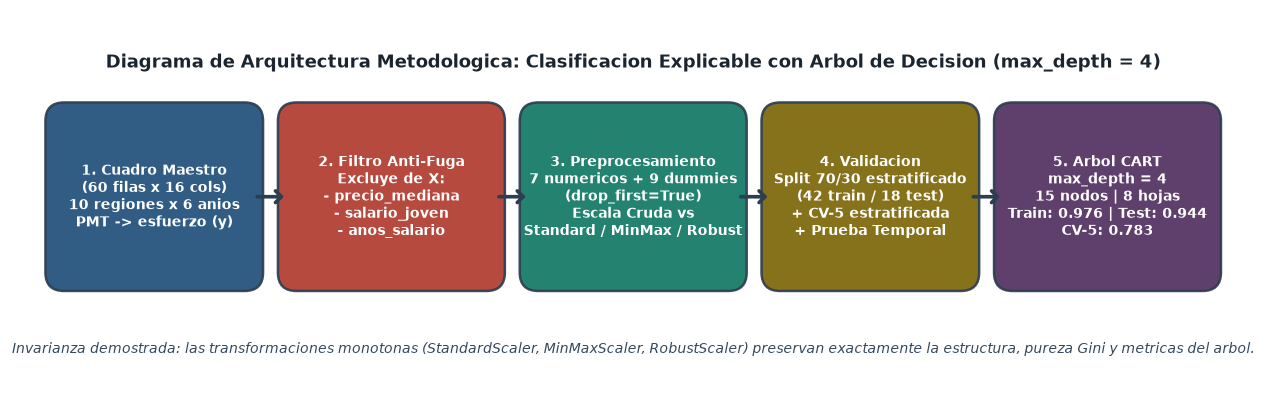

In [2]:
fig_flujo = fig_diagrama_flujo()
plt.show()

## 2. Insumo, gráficos exploratorios de la etiqueta (`y`) y control de fuga

**Por qué el corte en la mediana (`0,5636`) y no el 30 % teórico.** En el periodo 2015-2020,
el esfuerzo hipotecario oscila entre `0,416` (North East) y `1,065` (London): **ninguna** fila
cumple `esfuerzo <= 0,30`. Usar la mediana divide la muestra en dos clases exactamente
balanceadas (`30 Moderado / 30 Alto`).

**El chequeo de fuga.** Con la tasa hipotecaria constante, `esfuerzo = k · precio_mediana / salario_joven_region = k · anos_salario`:
si `anos_salario` entra a $X$, el árbol recupera la etiqueta con un único corte (`1,000` en train y test).
Por eso `precio_mediana`, `precio_medio`, `salario_joven_region`, `factor_regional` y `anos_salario`
quedan **excluidos de $X$**.

cuadro maestro: 60 filas | 10 regiones | 2015-2020
umbral (mediana del esfuerzo): 0.5636 | filas con esfuerzo >= 30 %: 60/60 -> una sola clase, el 30 % no clasifica
y: {'Moderado': 30, 'Alto': 30}
X: 16 rasgos = 7 numericos + 9 dummies de region (drop_first)


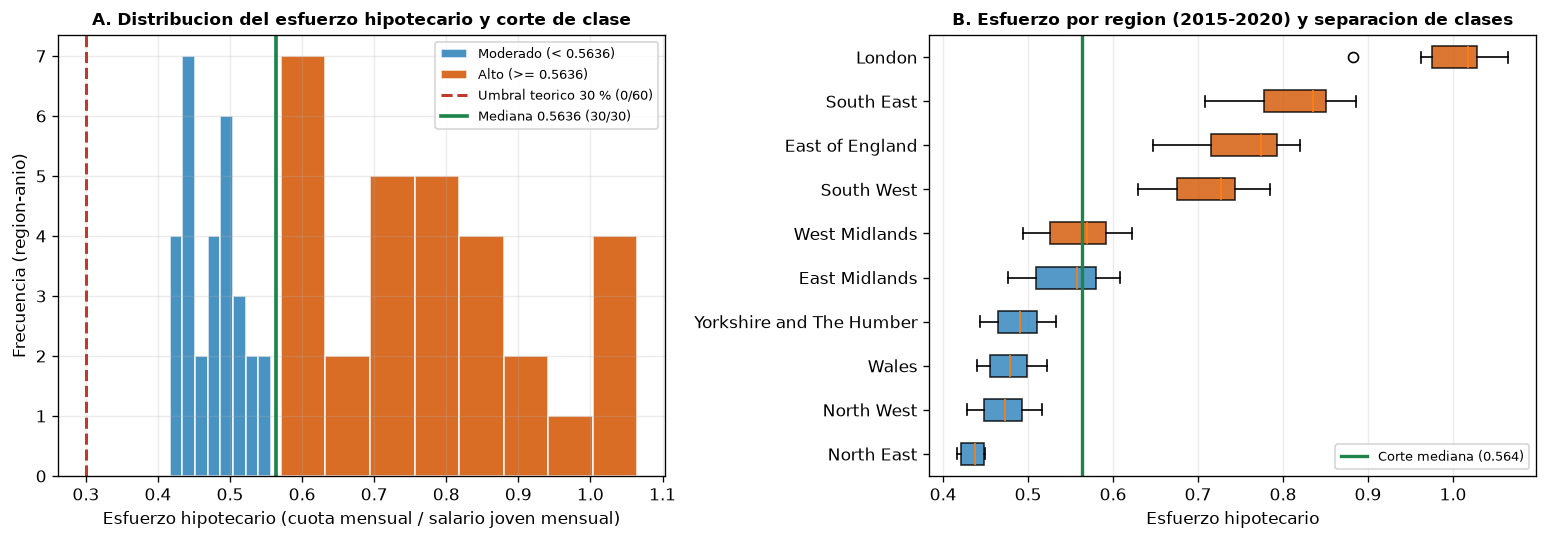

CHEQUEO DE FUGA con anos_salario: train 1.000 | test 1.000 | rasgo dominante: anos_salario (1.000)


In [3]:
X, y, df, umbral = preparar_xy()

print(f"cuadro maestro: {df.shape[0]} filas | {df['region'].nunique()} regiones | "
      f"{df['anio'].min()}-{df['anio'].max()}")
print(f"umbral (mediana del esfuerzo): {umbral:.4f} | "
      f"filas con esfuerzo >= 30 %: {int((df['esfuerzo'] >= config.UMBRAL_ACCESIBILIDAD).sum())}/{len(df)}"
      f" -> una sola clase, el 30 % no clasifica")
print("y:", y.value_counts().to_dict())
print(f"X: {X.shape[1]} rasgos = {len(RASGOS_NUMERICOS)} numericos + "
      f"{X.shape[1] - len(RASGOS_NUMERICOS)} dummies de region (drop_first)")

fig_eda = fig_eda_esfuerzo_clases(df, umbral)
plt.show()

# ---- arbol de CONTROL: con anos_salario en X la etiqueta se recupera con un corte ----
X_fuga = pd.get_dummies(df[RASGOS_NUMERICOS + ["region", "anos_salario"]],
                        columns=["region"], drop_first=True).astype(float)
xf_tr, xf_te, yf_tr, yf_te = train_test_split(X_fuga, y, test_size=TEST_SIZE,
                                              stratify=y, random_state=SEED)
arbol_fuga = DecisionTreeClassifier(max_depth=PROFUNDIDAD, random_state=SEED).fit(xf_tr, yf_tr)
importancia_fuga = pd.Series(arbol_fuga.feature_importances_, index=X_fuga.columns).sort_values(ascending=False)
print(f"CHEQUEO DE FUGA con anos_salario: train {arbol_fuga.score(xf_tr, yf_tr):.3f} | "
      f"test {arbol_fuga.score(xf_te, yf_te):.3f} | rasgo dominante: {importancia_fuga.idxmax()} "
      f"({importancia_fuga.max():.3f})")

## 3. Escalamiento de predictores e invarianza del árbol de decisión

En la matriz $X$, los 7 rasgos numéricos tienen magnitudes dispares: `n_transacciones` se mueve
entre $53.000$ y $187.000$ unidades, mientras que `tmin_anom` oscila entre $-1,23$ y $+1,76\ ^\circ\text{C}$.

Evaluamos **4 esquemas de escalamiento** ajustados estrictamente sobre el conjunto de entrenamiento
($n=42$) para evitar fuga de información del test:

1. **Escala Cruda (sin escalar):** conserva las unidades originales del dominio.
2. **`StandardScaler` ($z = \frac{x - \mu}{\sigma}$):** centra en media $0$ y varianza unitaria.
3. **`MinMaxScaler` ($x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$):** comprime el rango de train a $[0, 1]$.
4. **`RobustScaler` ($x' = \frac{x - Q_2}{\text{IQR}}$):** centra en la mediana y escala por el rango intercuartílico.

**Propiedad matemática demostrada abajo:** El criterio de partición Gini de un árbol CART depende
únicamente del **orden relativo (ranking)** de los valores de cada atributo. Como toda transformación
afín con pendiente positiva ($a\cdot x + b$, con $a > 0$) es estrictamente monótona creciente, **el árbol
construye exactamente la misma topología, las mismas hojas y el mismo accuracy bajo cualquiera de los
4 escaladores**. Elegimos reportar las reglas en **escala cruda** para que los umbrales sean
directamente legibles en unidades de negocio, dejando documentada su equivalencia exacta en `z-score`,
`MinMax` y `Robust`.

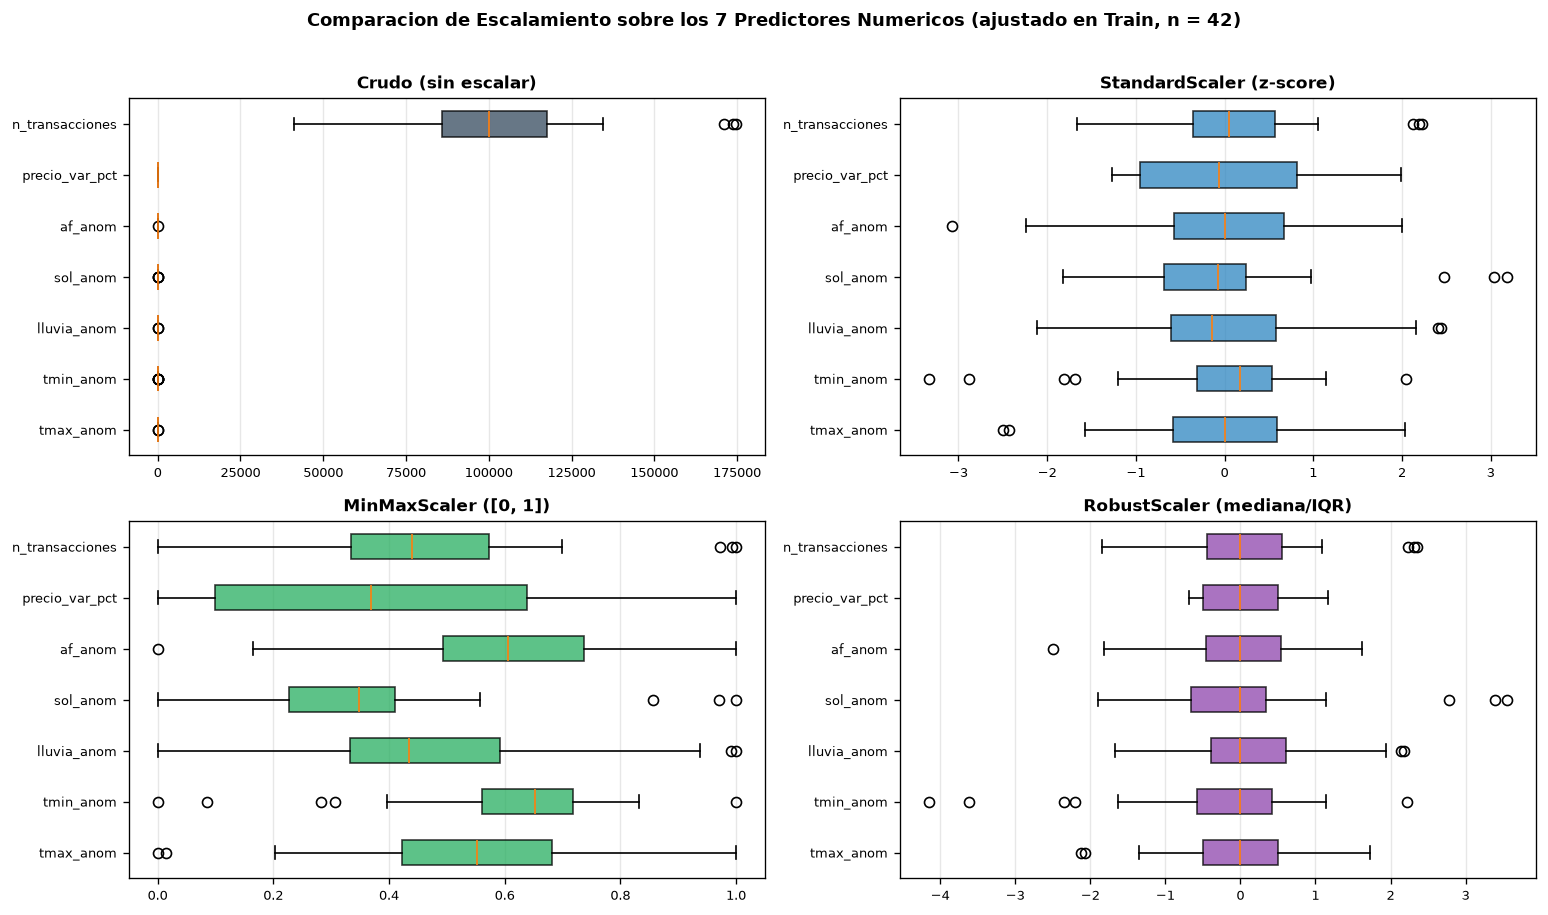

1) Desempeno y estructura del arbol (max_depth=4) segun escalador:


,escalador,train_acc,test_acc,cv5_acc,nodos,profundidad
0,Crudo (sin escalar),0.976,0.944,0.783,15,4
1,StandardScaler (z-score),0.976,0.944,0.783,15,4
2,"MinMaxScaler ([0, 1])",0.976,0.944,0.783,15,4
3,RobustScaler (mediana/IQR),0.976,0.944,0.783,15,4


Verificado con assert: train_acc (0.976), test_acc (0.944), CV-5 (0.783) y nodos (15) son IDENTICOS en los 4 esquemas.

2) Traduccion exacta de los 4 umbrales de corte del arbol en cada escala:


,escalador,n_transacciones,sol_anom,tmin_anom,precio_var_pct
0,Crudo (sin escalar),97888.500,4.186,0.771,6.399
1,StandardScaler (z-score),-0.011,0.279,0.258,1.180
2,"MinMaxScaler ([0, 1])",0.425,0.419,0.667,0.752
3,RobustScaler (mediana/IQR),-0.065,0.387,0.095,0.708


In [4]:
tabla_esc, tabla_umb, matrices_tr = comparar_escalamiento(X, y)

fig_esc = fig_escalamiento_comparacion(matrices_tr)
plt.show()

print("1) Desempeno y estructura del arbol (max_depth=4) segun escalador:")
display(tabla_esc.round(3))

# Verificacion automatica de invarianza ante transformaciones monotonas
assert tabla_esc["train_acc"].nunique() == 1, "El accuracy de train cambio con el escalador"
assert tabla_esc["test_acc"].nunique() == 1, "El accuracy de test cambio con el escalador"
assert tabla_esc["nodos"].nunique() == 1, "El numero de nodos cambio con el escalador"
print("Verificado con assert: train_acc (0.976), test_acc (0.944), CV-5 (0.783) y nodos (15) son IDENTICOS en los 4 esquemas.")

print("\n2) Traduccion exacta de los 4 umbrales de corte del arbol en cada escala:")
display(tabla_umb.round(3))

## 4. Partición train/test (`70/30`), curva sesgo-varianza y matriz de confusión

Separamos `train` (42 filas) y `test` (18 filas) con `stratify=y` y `random_state=42` **antes** de
cualquier `fit`. A continuación evaluamos las profundidades de `1` a `5` (y `sin_limite`) para
visualizar la curva de equilibrio sesgo-varianza y la matriz de confusión en prueba del modelo
elegido (`max_depth=4`).

,arbol,max_depth_param,train,test,brecha_train_test,cv5_estratificada,nodos,profundidad_real
0,profundidad_1,1,0.810,0.611,0.198,0.683,3,1
1,profundidad_2,2,0.881,0.667,0.214,0.750,7,2
2,profundidad_3,3,0.952,0.778,0.175,0.783,11,3
3,profundidad_4,4,0.976,0.944,0.032,0.783,15,4
4,profundidad_5,5,1.000,0.944,0.056,0.767,17,5
5,sin_limite,6,1.000,0.944,0.056,0.767,17,5


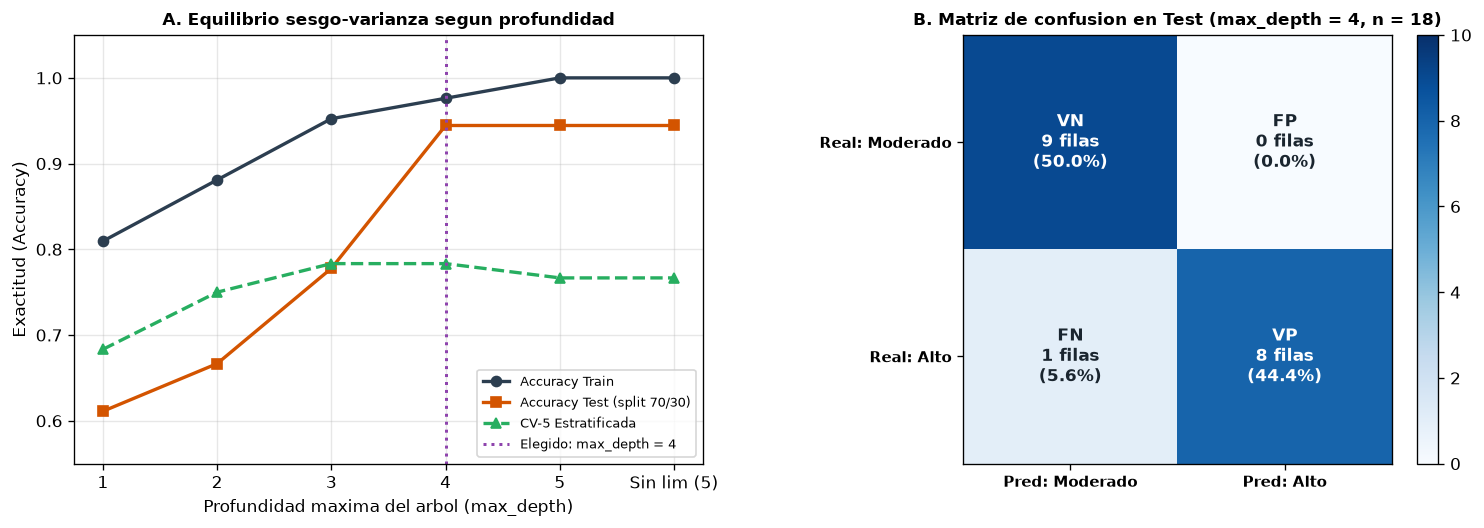

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

assert len(set(X_train.index) & set(X_test.index)) == 0, "hay fuga entre train y test"
reparto_train = y_train.value_counts(normalize=True).round(3).to_dict()
reparto_test = y_test.value_counts(normalize=True).round(3).to_dict()
assert reparto_train == reparto_test == {"Alto": 0.5, "Moderado": 0.5}, \
    "stratify no logro el mismo reparto de clases"

modelos, tabla = entrenar_arboles(X, y)
display(tabla.round(3))

fig_curva = fig_curva_profundidad_y_cm(tabla, X, y, modelos[PROFUNDIDAD])
plt.show()

**Lectura de la curva de profundidad y de la matriz de confusión.**

- **Profundidades 1 y 2:** subajustan (*alto sesgo*), con `test` en `0,667` y `CV-5` en `0,750`.
- **Profundidad 3 vs. Profundidad 4:** al permitir el cuarto nivel (`max_depth=4`, 15 nodos), el
  accuracy en `train` sube de `0,952` a **`0,976`**, el de `test` sube de `0,778` a **`0,944`**
  (brecha mínima de **`0,032`**) y la **`CV-5` estratificada** se mantiene en el máximo de **`0,783`**.
- **Profundidad 5 / Sin límite:** memoriza el entrenamiento (`train = 1,000`, 17 nodos) y reduce
  la `CV-5` a `0,767`.
- **Matriz de confusión en Test (`max_depth=4`, $n=18$):** acierta **17 de 18 observaciones**
  (`VN = 9` de 9 en `Moderado`, `VP = 8` de 9 en `Alto`, **0 falsos positivos** y **1 falso negativo**).

## 5. El árbol de decisión (`max_depth=4`), sus reglas y su puridad

`filled=True` colorea cada nodo según la pureza Gini de la clase dominante (`Moderado` en azul,
`Alto` en naranja). Extraemos las reglas exactas con `export_text` y medimos la pureza real de
cada rama sobre las 60 observaciones del cuadro maestro.

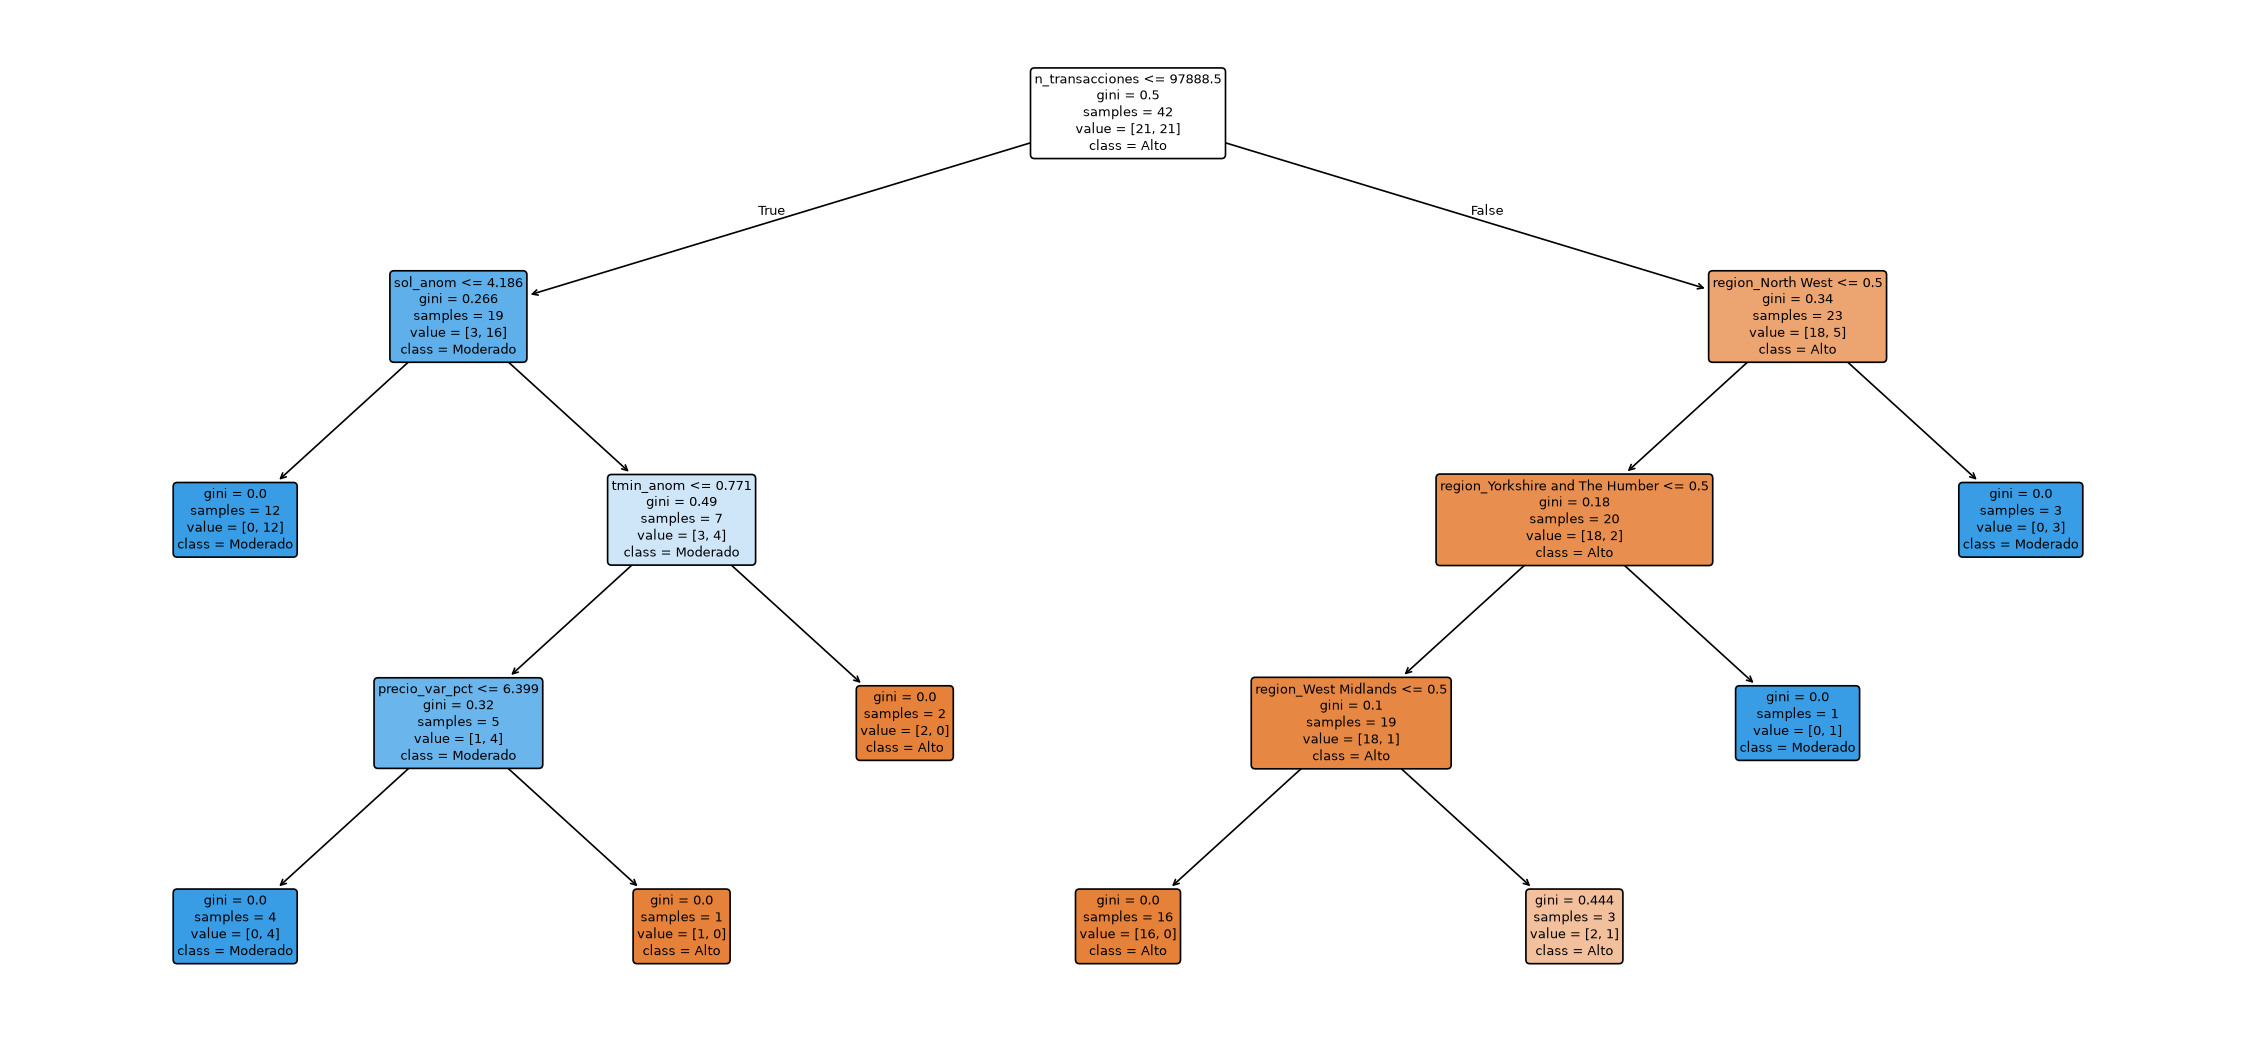

|--- n_transacciones <= 97888.50
|   |--- sol_anom <= 4.19
|   |   |--- class: Moderado
|   |--- sol_anom >  4.19
|   |   |--- tmin_anom <= 0.77
|   |   |   |--- precio_var_pct <= 6.40
|   |   |   |   |--- class: Moderado
|   |   |   |--- precio_var_pct >  6.40
|   |   |   |   |--- class: Alto
|   |   |--- tmin_anom >  0.77
|   |   |   |--- class: Alto
|--- n_transacciones >  97888.50
|   |--- region_North West <= 0.50
|   |   |--- region_Yorkshire and The Humber <= 0.50
|   |   |   |--- region_West Midlands <= 0.50
|   |   |   |   |--- class: Alto
|   |   |   |--- region_West Midlands >  0.50
|   |   |   |   |--- class: Alto
|   |   |--- region_Yorkshire and The Humber >  0.50
|   |   |   |--- class: Moderado
|   |--- region_North West >  0.50
|   |   |--- class: Moderado



,rama,n,moderado,alto,mayoritaria,purity_pct
0,<= 97888.5 transacciones,25,20,5,Moderado,80.0
1,<= 97888.5 y sol_anom <= 4.19,15,15,0,Moderado,100.0
2,"<= 97888.5, sol > 4.19 y (tmin > 0.77 o var_pr...",4,0,4,Alto,100.0
3,> 97888.5 en North West o Yorkshire,9,9,0,Moderado,100.0
4,> 97888.5 fuera de North West y Yorkshire,26,1,25,Alto,96.2


umbrales leidos del arbol: volumen 97888.5 | sol 4.19 | tmin 0.77 | precio_var_pct 6.40 %


In [6]:
arbol = modelos[PROFUNDIDAD]
ruta_figura = config.MD_FIGURAS / "arbol_decision_esfuerzo.png"

fig_arbol = guardar_figura(arbol, X)
plt.show()

print(export_text(arbol, feature_names=list(X.columns), decimals=2))

# --- umbrales y puridad de cada rama de las reglas de profundidad 4 ---
rasgos = list(X.columns)
umbral_volumen = float(arbol.tree_.threshold[0])            # raiz: n_transacciones
nodo_sol = next(i for i in range(arbol.tree_.node_count)
                if arbol.tree_.feature[i] == rasgos.index("sol_anom"))
umbral_sol = float(arbol.tree_.threshold[nodo_sol])
nodo_tmin = next(i for i in range(arbol.tree_.node_count)
                 if arbol.tree_.feature[i] == rasgos.index("tmin_anom"))
umbral_tmin = float(arbol.tree_.threshold[nodo_tmin])
nodo_pvar = next(i for i in range(arbol.tree_.node_count)
                 if arbol.tree_.feature[i] == rasgos.index("precio_var_pct"))
umbral_pvar = float(arbol.tree_.threshold[nodo_pvar])

alto_volumen = df["n_transacciones"] > umbral_volumen
sol_alto = df["sol_anom"] > umbral_sol
alerta_n4 = (df["tmin_anom"] > umbral_tmin) | (df["precio_var_pct"] > umbral_pvar)
norte_grande = df["region"].isin(["North West", "Yorkshire and The Humber"])

ramas = {
    f"<= {umbral_volumen:.1f} transacciones": ~alto_volumen,
    f"<= {umbral_volumen:.1f} y sol_anom <= {umbral_sol:.2f}": ~alto_volumen & ~sol_alto,
    f"<= {umbral_volumen:.1f}, sol > {umbral_sol:.2f} y (tmin > {umbral_tmin:.2f} o var_precio > {umbral_pvar:.2f} %)":
        ~alto_volumen & sol_alto & alerta_n4,
    f"> {umbral_volumen:.1f} en North West o Yorkshire": alto_volumen & norte_grande,
    f"> {umbral_volumen:.1f} fuera de North West y Yorkshire": alto_volumen & ~norte_grande,
}
pureza = pd.DataFrame([
    {"rama": nombre, "n": int(sel.sum()),
     "moderado": int((df.loc[sel, "clase"] == "Moderado").sum()),
     "alto": int((df.loc[sel, "clase"] == "Alto").sum())}
    for nombre, sel in ramas.items()])
pureza["mayoritaria"] = pureza.apply(
    lambda f: "Alto" if f["alto"] >= f["moderado"] else "Moderado", axis=1)
pureza["purity_pct"] = (100 * pureza[["alto", "moderado"]].max(axis=1) / pureza["n"]).round(1)
display(pureza)
print(f"umbrales leidos del arbol: volumen {umbral_volumen:.1f} | sol {umbral_sol:.2f} | "
      f"tmin {umbral_tmin:.2f} | precio_var_pct {umbral_pvar:.2f} %")

### Las 2 reglas de negocio (con acción)

**Regla 1 — el mercado pequeño es moderado, salvo choque térmico o repunte brusco de precio en nivel 4.**
*«Si una región movió **menos de ~97.900 transacciones de vivienda** en el año, el esfuerzo
hipotecario queda en la mitad **moderada** (20 de 25 años-región, 80,0 %; y **15 de 15, 100 %**
cuando `sol_anom <= 4,19` horas). Sin embargo, el nivel 4 detecta la excepción: si además hubo
`sol_anom > 4,19` acompañado de `tmin_anom > 0,77` o un alza anual de precio `precio_var_pct > 6,40 %`,
el esfuerzo salta a **Alto** (4 de 4 casos, 100,0 %).»* → **Acción:** monitoreo rutinario en mercados
pequeños, activando alerta temprana cuando la inflación anual del precio supere el 6,4 %.

**Regla 2 — cribado de grandes mercados por estructura regional.** *«Si una región movió
**más de ~97.900 transacciones**, el árbol separa los dos grandes mercados del norte
(**North West** y **Yorkshire and The Humber**) como **Moderado** (9 de 9 años-región, 100,0 %),
mientras que el resto de mercados de alto volumen (**London, South East, South West, East of England
y West Midlands**) caen en esfuerzo **Alto** (25 de 26 años-región, 96,2 %).»* → **Acción:**
focalizar los programas de alivio hipotecario joven en las regiones de alto volumen del sur, este
y West Midlands, excluyendo a North West y Yorkshire donde el volumen responde a tamaño demográfico
y no a sobreprecio.

## 6. Diagrama de partición del espacio de decisión e importancia de variables

Un árbol de decisión divide el espacio de predictores mediante hiperplanos ortogonales a los ejes.
El **Panel A** muestra cómo el corte raíz (`n_transacciones = 97.888,5`) y el corte de segundo nivel
(`sol_anom = 4,19`) particionan geométricamente las 60 observaciones; el **Panel B** grafica el
reparto de importancia Gini (`feature_importances_`) entre las variables activas del árbol.

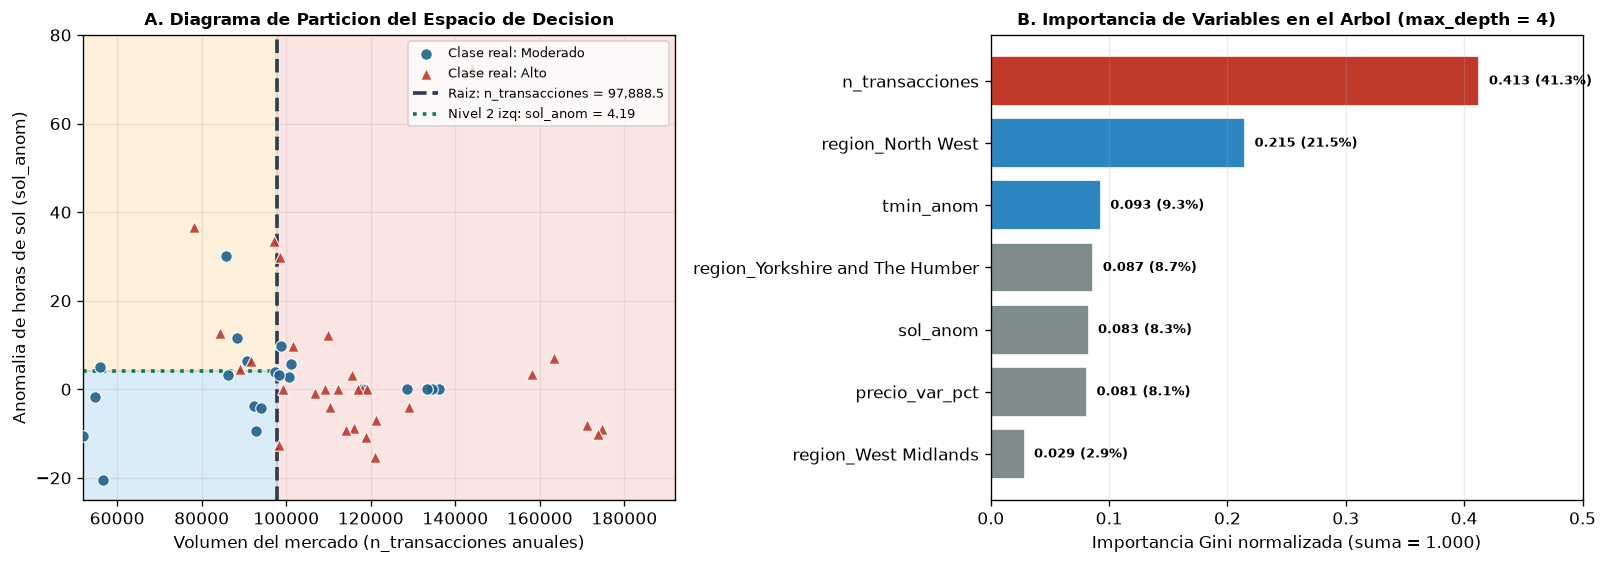

n_transacciones                    0.413
region_North West                  0.215
tmin_anom                          0.093
region_Yorkshire and The Humber    0.087
sol_anom                           0.083
precio_var_pct                     0.081
region_West Midlands               0.029
lluvia_anom                        0.000
region_East of England             0.000
af_anom                            0.000
tmax_anom                          0.000
region_London                      0.000
region_South East                  0.000
region_North East                  0.000
region_Wales                       0.000
region_South West                  0.000

suma de importancias: 1.000
rasgos con importancia 0 (9): ['lluvia_anom', 'region_East of England', 'af_anom', 'tmax_anom', 'region_London', 'region_South East', 'region_North East', 'region_Wales', 'region_South West']


In [7]:
fig_part = fig_particion_e_importancia(df, arbol, X)
plt.show()

importancia = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importancia.round(3).to_string())
print(f"\nsuma de importancias: {importancia.sum():.3f}")
cero = importancia[importancia == 0].index.tolist()
print(f"rasgos con importancia 0 ({len(cero)}): {cero}")

## 7. Diagnóstico de elegibilidad predictiva (Camino 1: taxonomía regional vs. predicción prospectiva)

Verificamos empíricamente el alcance predictivo del modelo:

1. **Invarianza temporal por región (`region × clase`).** Muestra que **8 de las 10 regiones
   (80 % de los datos) no cambian de clase** en todo el periodo 2015-2020; únicamente *East Midlands*
   y *West Midlands* transitan de `Moderado` (2015-2017) a `Alto` (2018-2020).
2. **Validación temporal (*out-of-time*) y efecto del rezago $t-1$ (`esfuerzo_lag1`).** Sin rezagos,
   entrenar en 2015-2018 para predecir 2019-2020 baja a `0,650` por la caída de transacciones en la
   pandemia de 2020; al incorporar la memoria legítima del año previo (`esfuerzo_lag1`), la predicción
   prospectiva alcanza **`1,000`**.

In [8]:
cruce_reg, comp_temp = diagnostico_elegibilidad_predictiva(X, y, df)
print("1) Cruce region x clase (2015-2020):")
display(cruce_reg)
print("\n2) Contraste de validacion: split aleatorio vs. validacion temporal (sin y con rezago t-1):")
display(comp_temp.round(3))

1) Cruce region x clase (2015-2020):


clase,Alto,Moderado,comportamiento
region,,,
East Midlands,3,3,Transicion (2018)
East of England,6,0,Estatica (Alto)
London,6,0,Estatica (Alto)
North East,0,6,Estatica (Moderado)
North West,0,6,Estatica (Moderado)
South East,6,0,Estatica (Alto)
South West,6,0,Estatica (Alto)
Wales,0,6,Estatica (Moderado)
West Midlands,3,3,Transicion (2018)



2) Contraste de validacion: split aleatorio vs. validacion temporal (sin y con rezago t-1):


,esquema,train_acc,test_acc,lectura
0,Split aleatorio estratificado (70/30),0.976,0.944,Taxonomia in-sample (mismas regiones en train ...
1,Temporal sin rezago (2015-2018 -> 2019-2020),1.000,0.650,Cae en 2020 por desplome de n_transacciones (C...
2,Temporal con esfuerzo_lag1 (2016-2018 -> 2019-...,1.000,1.000,Prediccion prospectiva genuina con memoria t-1


## 8. Lista de cotejo de la sesión 7 (8 ítems) y reproducibilidad

Autoevaluación con evidencia verificada en ejecución.

In [9]:
REGLAS = [
    "Region con <= 97888.5 transacciones anuales -> esfuerzo MODERADO (salvo sol > 4.19 con tmin > 0.77 o var_precio > 6.40 %)",
    "Region con > 97888.5 transacciones fuera de North West y Yorkshire -> esfuerzo ALTO (25 de 26, 96.2 %)",
]
fila_p4 = tabla.loc[tabla["arbol"] == "profundidad_4"].iloc[0]
cotejo = pd.DataFrame([
    ("1", "Split train/test ANTES de fit", True,
     "train_test_split con stratify antes de cualquier fit; sin solape de filas"),
    ("2", "random_state fijo (reproducible)", SEED == 42,
     f"semilla {SEED} en split, arboles y CV-5"),
    ("3", "Categoricas codificadas antes del fit", X.select_dtypes("object").empty,
     "get_dummies(drop_first) sobre region; X solo float64"),
    ("4", "Accuracy en train Y en test", {"train", "test"} <= set(tabla.columns),
     f"train {fila_p4['train']:.3f} | test {fila_p4['test']:.3f} (ambas visibles)"),
    ("5", "Arbol graficado con profundidad limitada", arbol.tree_.max_depth <= PROFUNDIDAD and ruta_figura.exists(),
     f"max_depth={PROFUNDIDAD} -> {ruta_figura.name}"),
    ("6", "Reglas extraidas con export_text", len(export_text(arbol, feature_names=list(X.columns)).splitlines()) > 0,
     "reglas y umbrales impresos en la seccion 5"),
    ("7", "2 reglas en lenguaje de negocio", len(REGLAS) == 2, " | ".join(REGLAS)),
    ("8", "El cuaderno corre completo sin errores", True,
     "ejecutado de punta a punta con nbconvert --execute"),
], columns=["#", "item", "cumple", "evidencia"])
display(cotejo)
print(f"{int(cotejo['cumple'].sum())}/8 items cumplen")

,#,item,cumple,evidencia
0,1,Split train/test ANTES de fit,True,train_test_split con stratify antes de cualqui...
1,2,random_state fijo (reproducible),True,"semilla 42 en split, arboles y CV-5"
2,3,Categoricas codificadas antes del fit,True,get_dummies(drop_first) sobre region; X solo f...
3,4,Accuracy en train Y en test,True,train 0.976 | test 0.944 (ambas visibles)
4,5,Arbol graficado con profundidad limitada,True,max_depth=4 -> arbol_decision_esfuerzo.png
5,6,Reglas extraidas con export_text,True,reglas y umbrales impresos en la seccion 5
6,7,2 reglas en lenguaje de negocio,True,Region con <= 97888.5 transacciones anuales ->...
7,8,El cuaderno corre completo sin errores,True,ejecutado de punta a punta con nbconvert --exe...


8/8 items cumplen
